# Used Car Price Estimation Engine (Classification Model)

This project aims to classify used cars into predefined price categories using machine learning techniques.

The model predicts the price segment of a car based on features such as year, fuel type, transmission, and usage patterns.

## Problem Statement

The objective of this project is to build a machine learning model that predicts the price category of a used car.

Instead of predicting an exact price, the problem is formulated as a **classification task** using predefined price segments available in the dataset.

This approach aligns with real-world scenarios where categorized pricing is often more useful than exact predictions.

## Target Variable

The target variable used in this project is `price_segment_new`, which is already present in the dataset.

This variable represents categorized price ranges of used cars.

### Why use predefined segments?
- Avoids arbitrary binning decisions
- Maintains dataset consistency
- Reflects domain-informed categorization
- Prevents class imbalance due to poor binning

Thus, no manual binning techniques (such as `cut` or `qcut`) were applied in this project.

## Dataset Description

The dataset is sourced from the CarDekho dataset on Kaggle.

It includes features such as:
- Manufacturing year (myear)
- Kilometers driven (km)
- Fuel type
- Transmission type
- Ownership details
- Car name/title

The dataset also contains a pre-defined target variable (`price_segment_new`) representing price categories.

## Why Classification Instead of Regression?

While car price prediction is naturally a regression problem, this project uses a classification approach for the following reasons:

- Predicting exact prices can be sensitive to noise and outliers.
- Users often prefer **price ranges** (budget categories) rather than exact values.
- Classification simplifies decision-making for buyers and sellers.
- It improves robustness when data contains extreme variations.

Thus, the problem is reframed into predicting price categories.

## Data Cleaning Strategy (Overview)
- Handling missing values
- Converting string data into numeric formats
- Standardizing categorical variables
- Extracting features from text columns
- Handling outliers
- Encoding categorical features

## Imports & Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import joblib
from xgboost import XGBClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV


## Connect Drive to Colab to fetch the dataset
## Load the Dataset

In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)), low_memory=False)

df.shape


## Data Understanding

Before preprocessing, it is essential to understand the structure and quality of the dataset.

This includes:
- Checking data types
- Identifying missing values
- Understanding feature distributions
- Detecting inconsistencies in the dataset

This step guides all further preprocessing decisions.

In [ ]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

print("Dataset Info:")
df.info()

display(df.describe())

Dataset Shape: 37814 rows, 140 columns

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37814 entries, 0 to 37813
Columns: 140 entries, position to Ground Clearance Unladen
dtypes: bool(3), float64(10), int64(28), object(99)
memory usage: 39.6+ MB


,position,myear,ip,imgCount,modelId,centralVariantId,discountValue,msp,pageNo,views,...,city_id_new,max_engine_capacity_new,km_driven,used_carid,dealer_id,model_year,dynx_itemid_y,dynx_itemid2_y,dynx_totalvalue_y,min_engine_capacity_new
count,37814.000000,37814.000000,37814.000000,37814.000000,37814.000000,37814.000000,37814.000000,3.781400e+04,37814.000000,37814.000000,...,37814.000000,37761.000000,3.781400e+04,3.781400e+04,37814.0,37814.000000,3.781400e+04,37814.000000,3.781400e+04,37761.000000
mean,12.786349,2015.569472,0.010208,15.571005,813.535516,4244.333131,73.279764,5.426562e+01,76.330433,313.440736,...,176.556963,1438.638542,6.240934e+04,3.350110e+06,0.0,2015.569472,3.350110e+06,4244.126884,7.999081e+05,1438.638542
std,4.538626,3.779047,0.100518,8.358341,908.223696,2456.207209,2805.746196,7.477465e+03,34.703450,512.066193,...,162.452402,470.559461,5.847148e+04,4.822178e+04,0.0,3.779047,4.822178e+04,2456.445823,3.042944e+06,470.559461
min,1.000000,1983.000000,0.000000,0.000000,3.000000,3.000000,0.000000,0.000000e+00,2.000000,0.000000,...,2.000000,0.000000,1.010000e+02,2.123741e+06,0.0,1983.000000,2.123741e+06,3.000000,1.196300e+04,0.000000
25%,9.000000,2013.000000,0.000000,10.000000,262.000000,1689.000000,0.000000,0.000000e+00,55.000000,69.000000,...,66.000000,1197.000000,3.173950e+04,3.323254e+06,0.0,2013.000000,3.323254e+06,1682.000000,3.200000e+05,1197.000000
50%,13.000000,2016.000000,0.000000,15.000000,582.000000,4191.000000,0.000000,0.000000e+00,69.000000,166.000000,...,152.000000,1248.000000,5.672600e+04,3.366214e+06,0.0,2016.000000,3.366214e+06,4191.000000,5.250000e+05,1248.000000
75%,17.000000,2018.000000,0.000000,21.000000,834.000000,6373.000000,0.000000,0.000000e+00,100.000000,364.000000,...,243.000000,1582.000000,8.330775e+04,3.384768e+06,0.0,2018.000000,3.384768e+06,6373.000000,8.556565e+05,1582.000000
max,20.000000,2023.000000,1.000000,74.000000,3417.000000,9670.000000,200000.000000,1.093000e+06,163.000000,21102.000000,...,1721.000000,6749.000000,6.300000e+06,3.399050e+06,0.0,2023.000000,3.399050e+06,9670.000000,5.500006e+08,6749.000000


In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({'Missing Percentage (%)': missing_percent})

print("Columns with Missing Data:")
display(missing_df.head(20))

Columns with Missing Data:


,Missing Percentage (%)
originalLocation,100.000000
compare_car_details,100.000000
priceSaving,99.994711
brandingIcon,97.982229
Ground Clearance Unladen,94.308986
Compression Ratio,73.099910
BoreX Stroke,66.581160
Gross Weight,55.244089
Rear Tread,41.984450
Front Tread,41.981806


## Data Issues Identified

- Large number of missing values
- Mixed data types (numeric stored as text)
- Irrelevant columns (URLs, images, IDs)
- High dimensional dataset (~140 columns)

## Drop High Missing & Useless & Complex Text/ List Columns

In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100

high_missing_cols = missing_percent[missing_percent > 50].index.tolist()

print("Columns with >50% missing values:")
print(high_missing_cols)

Columns with >50% missing values:
['priceSaving', 'brandingIcon', 'BoreX Stroke', 'Gross Weight', 'originalLocation', 'compare_car_details', 'Compression Ratio', 'Ground Clearance Unladen']


In [ ]:
useless_keywords = ['id', 'url', 'image', 'img', 'sku', 'ip']

dynamic_useless_cols = []

for col in df.columns:
    if any(word in col.lower() for word in useless_keywords):
        dynamic_useless_cols.append(col)

print("Detected useless/system columns:")
print(dynamic_useless_cols)

Detected useless/system columns:
['ip', 'images', 'imgCount', 'modelId', 'vid', 'centralVariantId', 'usedCarId', 'usedCarSkuId', 'ucid', 'sid', 'emiwidget', 'dynx_itemid_x', 'dynx_itemid2_x', 'corporateId', 'Width', 'model_id_new', 'dealer_id_new', 'city_id_new', 'used_carid', 'dealer_id', 'dynx_itemid_y', 'dynx_itemid2_y']


In [ ]:
complex_text_cols = []

for col in df.columns:
    if 'feature' in col.lower() or 'spec' in col.lower():
        complex_text_cols.append(col)

print("Complex text columns:")
print(complex_text_cols)

Complex text columns:
['top_features', 'comfort_features', 'interior_features', 'exterior_features', 'safety_features']


In [ ]:
cols_to_drop = list(set(high_missing_cols + dynamic_useless_cols + complex_text_cols))

df.drop(columns=cols_to_drop, inplace=True, errors='ignore')

print("Total columns dropped:", len(cols_to_drop))
print("New Shape:", df.shape)

Total columns dropped: 35
New Shape: (37814, 105)


## Data Preprocessing

Data preprocessing is a crucial step to ensure data quality and improve model performance.

The following steps were performed:
- Handling missing values
- Encoding categorical variables
- Scaling numerical features
- Detecting and treating outliers

## Handling Missing Values

Missing values in numerical features were handled using **KNN Imputer**.

### Why KNN Imputer?
- Uses similarity between data points
- Preserves relationships between features
- More accurate than mean/median imputation

### Alternatives:
- Mean/Median Imputation (simpler but less accurate)
- Iterative Imputer (more complex)

KNN Imputer was chosen for better data representation.

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns


knn_imputer = KNNImputer(n_neighbors=5)

df[num_cols] = knn_imputer.fit_transform(df[num_cols])


for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Remaining Missing Values:", df.isnull().sum().sum())

Remaining Missing Values: 0


## Duplicates Handling

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Rows Found:", duplicates)

df.drop_duplicates(inplace=True)

print("New Shape After Removing Duplicates:", df.shape)

Duplicate Rows Found: 0
New Shape After Removing Duplicates: (37814, 105)


## Basic Data Cleaning

This step focuses on removing formatting inconsistencies such as extra spaces, mixed casing, unwanted symbols, and standardizing textual columns for better preprocessing.

In [ ]:
cat_cols = df.select_dtypes(include='object').columns
cat_cols


for col in cat_cols:
    df[col] = df[col].str.strip()

for col in cat_cols:
    df[col] = df[col].str.lower()


replace_vals = ['null', 'na', 'n/a', '--', 'unknown', '']

for col in cat_cols:
    df[col] = df[col].replace(replace_vals, np.nan)

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

## Advanced Data Cleaning

Several columns contained numerical values mixed with units or text (such as km, CC, bhp, kmpl, Nm).  
These columns were cleaned by extracting only numeric values and converting them into proper numerical format for analysis and model training.

In [ ]:
def extract_number(x):
    x = str(x)
    match = re.search(r'\d+\.?\d*', x)
    return float(match.group()) if match else np.nan


km_cols = ['km', 'kms_driven', 'kilometers_driven']

for col in km_cols:
    if col in df.columns:
        df[col] = df[col].astype(str)
        df[col] = df[col].str.replace(',', '', regex=True)
        df[col] = df[col].apply(extract_number)


numeric_text_cols = [
    'displacement',
    'max power',
    'max torque',
    'engine',
    'mileage',
    'compression ratio',
    'power'
]

for col in df.columns:
    if col.lower() in numeric_text_cols:
        df[col] = df[col].apply(extract_number)


for col in df.select_dtypes(include='object').columns:

    sample_values = df[col].dropna().astype(str).head(20)

    digit_ratio = sample_values.str.contains(r'\d').mean()

    if digit_ratio > 0.6:
        df[col] = df[col].apply(extract_number)

In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37814 entries, 0 to 37813
Columns: 105 entries, position to Alloy Wheel Size
dtypes: bool(3), float64(48), object(54)
memory usage: 29.5+ MB


,position,loc,myear,bt,tt,ft,km,pi,threesixty,dvn,...,exterior_color,min_engine_capacity_new,owner_type,price_segment_new,template_name_new,page_template,template_Type_new,experiment,Fuel Suppy System,Alloy Wheel Size
0,1.0,gomti nagar,2016.0,hatchback,manual,cng,69162.0,10.0,False,maruti wagon r lxi cng,...,silver,998.0,first,2.0,2.0,used car > detail page,used,control,mpfi,16.0
1,2.0,borivali west,2015.0,hatchback,manual,cng,45864.0,10.0,False,maruti celerio green vxi,...,grey,998.0,first,2.0,2.0,used car > detail page,used,control,intelligent-gas port injection,16.0
2,3.0,jasola,2015.0,sedan,manual,cng,81506.0,10.0,False,honda amaze s plus i-vtec,...,silver,1198.0,second,2.0,2.0,used car > detail page,used,control,mpfi,16.0
3,4.0,jasola,2013.0,hatchback,manual,cng,115893.0,2718888.0,False,maruti wagon r lxi cng,...,silver,998.0,second,2.0,2.0,used car > detail page,used,control,mpfi,13.0
4,5.0,mumbai g.p.o.,2022.0,muv,manual,cng,18900.0,10.0,False,maruti ertiga vxi cng,...,white,1462.0,first,10.0,2.0,used car > detail page,used,control,mpfi,16.0


## Feature Engineering

New features were created to enhance model performance:

### 1. Car Age
Calculated as:
car_age = current_year - manufacturing_year

This helps capture depreciation over time.

### 2. Brand Extraction
Extracted from the car name/title column by taking the first word.

This helps identify brand influence on pricing.

### 3. Average Yearly Usage
Computed as:
km_per_year = total_km / car_age

This reflects how intensively the car has been used.

### 4. First Owner Flag
A binary feature (`is_first_owner`) indicating whether the car has had only one owner.

This is important as first-owner cars typically have higher resale value.

In [ ]:
if 'myear' in df.columns:
    current_year = 2026
    df['car_age'] = current_year - df['myear']


name_cols = ['name', 'car_name', 'title']

for col in name_cols:
    if col in df.columns:
        df['brand'] = df[col].astype(str).str.split().str[0].str.lower()
        break


if 'km' in df.columns and 'car_age' in df.columns:
    df['km_per_year'] = df['km'] / df['car_age'].replace(0,1)


owner_cols = ['owner', 'ownership']

for col in owner_cols:
    if col in df.columns:
        df['is_first_owner'] = df[col].astype(str).str.contains('first', case=False).astype(int)

In [ ]:
df.head()

,position,loc,myear,bt,tt,ft,km,pi,threesixty,dvn,...,owner_type,price_segment_new,template_name_new,page_template,template_Type_new,experiment,Fuel Suppy System,Alloy Wheel Size,car_age,km_per_year
0,1.0,gomti nagar,2016.0,hatchback,manual,cng,69162.0,10.0,False,maruti wagon r lxi cng,...,first,2.0,2.0,used car > detail page,used,control,mpfi,16.0,10.0,6916.200000
1,2.0,borivali west,2015.0,hatchback,manual,cng,45864.0,10.0,False,maruti celerio green vxi,...,first,2.0,2.0,used car > detail page,used,control,intelligent-gas port injection,16.0,11.0,4169.454545
2,3.0,jasola,2015.0,sedan,manual,cng,81506.0,10.0,False,honda amaze s plus i-vtec,...,second,2.0,2.0,used car > detail page,used,control,mpfi,16.0,11.0,7409.636364
3,4.0,jasola,2013.0,hatchback,manual,cng,115893.0,2718888.0,False,maruti wagon r lxi cng,...,second,2.0,2.0,used car > detail page,used,control,mpfi,13.0,13.0,8914.846154
4,5.0,mumbai g.p.o.,2022.0,muv,manual,cng,18900.0,10.0,False,maruti ertiga vxi cng,...,first,10.0,2.0,used car > detail page,used,control,mpfi,16.0,4.0,4725.000000


## Outlier Detection

Outliers were detected using the **Interquartile Range (IQR) method**.

### Why IQR?
- Works well for skewed data
- Does not assume normal distribution
- Simple and robust

This method helps identify extreme values in features like price and kilometers driven.

## Outlier Treatment

Outliers were treated using **capping** instead of removal.

### Why Capping?
- Prevents data loss
- Reduces influence of extreme values
- Maintains dataset size

This ensures stable model training without discarding useful data.

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()


if 'price_segment_new' in num_cols:
    num_cols.remove('price_segment_new')

num_cols
def cap_outliers_iqr(column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[column] = np.where(df[column] < lower, lower, df[column])
    df[column] = np.where(df[column] > upper, upper, df[column])
for col in num_cols:
    cap_outliers_iqr(col)

print("Outlier capping completed.")
df[num_cols].describe().T

Outlier capping completed.


,count,mean,std,min,25%,50%,75%,max
position,37814.0,12.786349,4.538626,1.000000,9.000000,13.000000,17.00,2.000000e+01
myear,37814.0,2015.584307,3.727064,2005.500000,2013.000000,2016.000000,2018.00,2.023000e+03
km,37814.0,61013.886358,37230.590441,101.000000,31739.500000,56727.000000,83307.75,1.606601e+05
pi,37814.0,10.000000,0.000000,10.000000,10.000000,10.000000,10.00,1.000000e+01
vlink,37814.0,68.032713,99.157792,0.000000,1.800000,8.000000,99.00,2.448000e+02
price,37814.0,6.928287,4.846099,1.000000,3.300000,5.470000,9.00,1.755000e+01
pu,37814.0,6.584149,5.026268,1.000000,3.000000,5.000000,9.00,1.800000e+01
discountValue,37814.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000e+00
msp,37814.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000e+00
pageNo,37814.0,76.330433,34.703450,2.000000,55.000000,69.000000,100.00,1.630000e+02


## Hybrid Encoding of Categorical Variables

A hybrid encoding strategy was used:

- One-Hot Encoding for low-cardinality nominal features
- Ordinal mapping for ownership-related ordered categories
- Label Encoding for high-cardinality categorical columns

This approach balances model performance and dimensional efficiency.

In [ ]:
cat_cols = df.select_dtypes(include='object').columns.tolist()

# 🔹 1. Ordinal Encoding for Owner
owner_map = {
    'first owner': 1,
    'second owner': 2,
    'third owner': 3,
    'fourth owner': 4,
    'test drive car': 0
}

for col in ['owner', 'ownership']:
    if col in df.columns:
        df[col] = df[col].str.lower().map(owner_map)

# 🔹 2. One-Hot Encoding for Low Cardinal Columns
one_hot_cols = []

for col in ['fuel', 'fuel_type', 'transmission', 'seller_type']:
    if col in df.columns:
        one_hot_cols.append(col)

df = pd.get_dummies(df, columns=one_hot_cols, drop_first=True)

# 🔹 3. Label Encoding for Remaining Columns
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

remaining_cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in remaining_cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print("Encoding completed.")
df.head()

Encoding completed.


,position,loc,myear,bt,tt,ft,km,pi,threesixty,dvn,...,template_Type_new,experiment,Fuel Suppy System,Alloy Wheel Size,car_age,km_per_year,fuel_type_diesel,fuel_type_electric,fuel_type_lpg,fuel_type_petrol
0,1.0,115,2016.0,2,1,0,69162.0,10.0,False,2562,...,0,0,45,16.0,10.0,6916.200000,False,False,False,False
1,2.0,61,2015.0,2,1,0,45864.0,10.0,False,2143,...,0,0,42,16.0,11.0,4169.454545,False,False,False,False
2,3.0,148,2015.0,8,1,0,81506.0,10.0,False,716,...,0,0,45,16.0,11.0,7409.636364,False,False,False,False
3,4.0,148,2013.0,2,1,0,115893.0,10.0,False,2562,...,0,0,45,13.5,13.0,8914.846154,False,False,False,False
4,5.0,237,2022.0,6,1,0,18900.0,10.0,False,2288,...,0,0,45,16.0,4.0,4725.000000,False,False,False,False


In [ ]:
df.head()

,position,loc,myear,bt,tt,ft,km,pi,threesixty,dvn,...,template_Type_new,experiment,Fuel Suppy System,Alloy Wheel Size,car_age,km_per_year,fuel_type_diesel,fuel_type_electric,fuel_type_lpg,fuel_type_petrol
0,1.0,115,2016.0,2,1,0,69162.0,10.0,False,2562,...,0,0,45,16.0,10.0,6916.200000,False,False,False,False
1,2.0,61,2015.0,2,1,0,45864.0,10.0,False,2143,...,0,0,42,16.0,11.0,4169.454545,False,False,False,False
2,3.0,148,2015.0,8,1,0,81506.0,10.0,False,716,...,0,0,45,16.0,11.0,7409.636364,False,False,False,False
3,4.0,148,2013.0,2,1,0,115893.0,10.0,False,2562,...,0,0,45,13.5,13.0,8914.846154,False,False,False,False
4,5.0,237,2022.0,6,1,0,18900.0,10.0,False,2288,...,0,0,45,16.0,4.0,4725.000000,False,False,False,False


## Exploratory Data Analysis (EDA)

To better understand the dataset, visualizations are used to identify patterns, relationships, and distributions.

This helps in:
- Understanding feature importance
- Detecting outliers
- Identifying trends affecting price

### Distribution of Kilometers Driven

This plot shows the spread of vehicle usage after outlier treatment.  
It helps identify whether most cars are low, moderate, or high mileage vehicles.

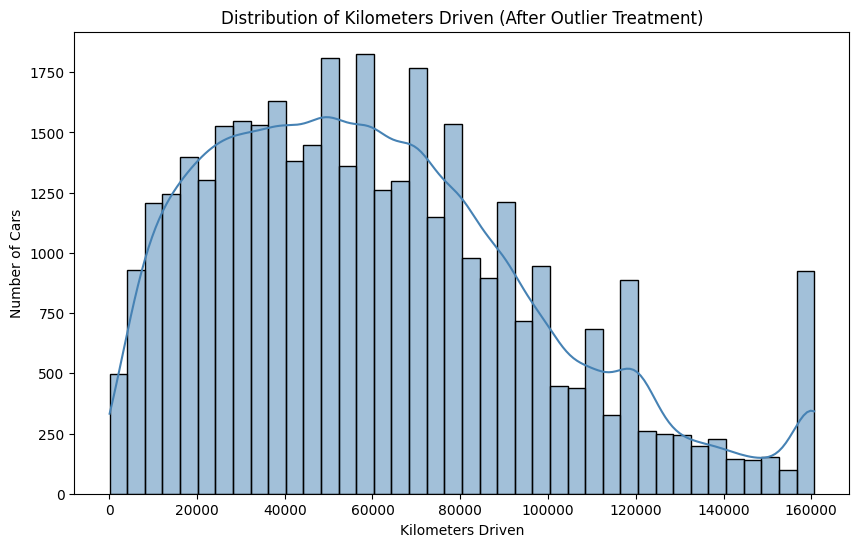

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['km'],
    bins=40,
    kde=True,
    color='steelblue'
)

plt.title("Distribution of Kilometers Driven (After Outlier Treatment)")
plt.xlabel("Kilometers Driven")
plt.ylabel("Number of Cars")

plt.show()

### Car Age vs Price Segment

This boxplot compares vehicle age across price categories.  
It helps evaluate whether newer cars belong to higher price segments.

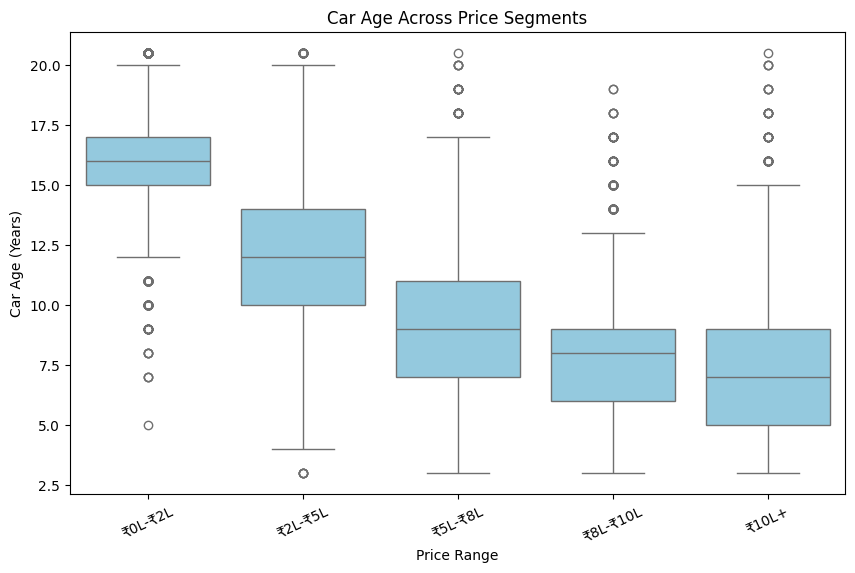

In [ ]:
plt.figure(figsize=(10,6))

segment_order = [0.0, 2.0, 5.0, 8.0, 10.0]

ax = sns.boxplot(
    x='price_segment_new',
    y='car_age',
    data=df,
    order=segment_order,
    color='skyblue'
)


ax.set_xticks(range(len(segment_order)))
ax.set_xticklabels([
    "₹0L-₹2L",
    "₹2L-₹5L",
    "₹5L-₹8L",
    "₹8L-₹10L",
    "₹10L+"
])

plt.title("Car Age Across Price Segments")
plt.xlabel("Price Range")
plt.ylabel("Car Age (Years)")

plt.xticks(rotation=25)
plt.show()

### Correlation Heatmap of Important Features

This heatmap displays relationships among the most influential numerical variables and the target class.

It helps identify:

- Strong predictors of price range  
- Redundant correlated features  
- Useful variables for modeling

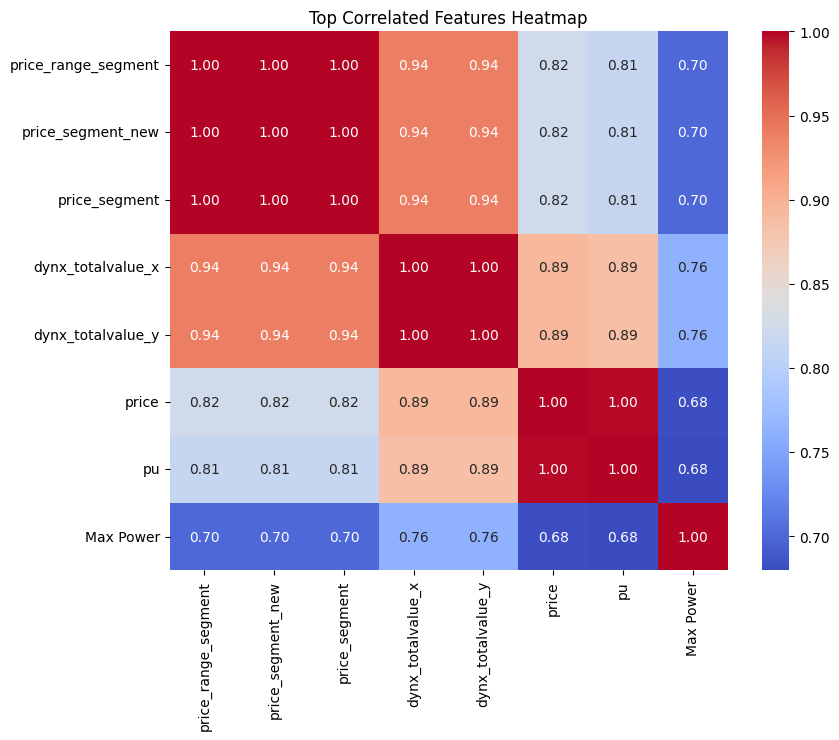

In [ ]:
corr = df.corr(numeric_only=True)['price_segment_new'].abs().sort_values(ascending=False)

top_cols = corr.head(8).index

plt.figure(figsize=(9,7))
sns.heatmap(df[top_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Top Correlated Features Heatmap")
plt.show()

### Price Segment Distribution

This chart shows the number of cars in each target price category.

It helps identify:

- Class balance  
- Majority/minority classes  
- Need for balancing techniques if required

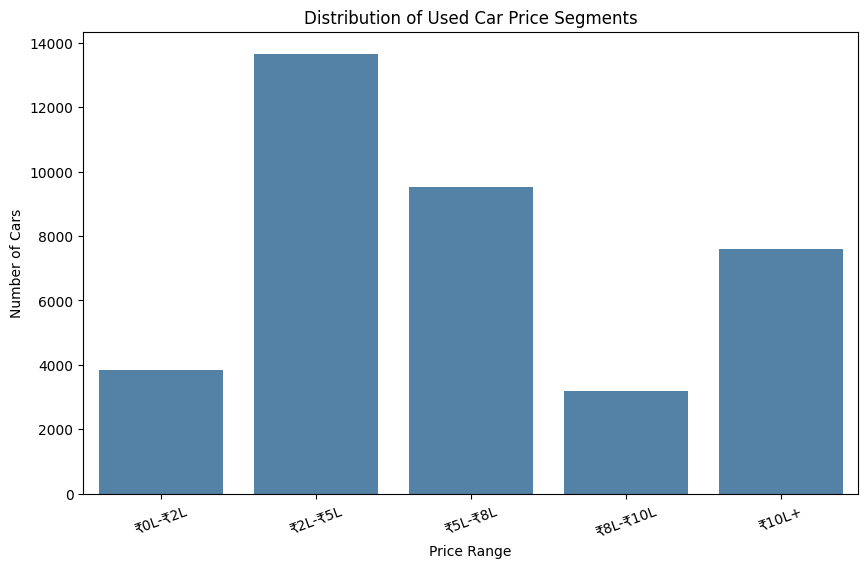

In [ ]:
plt.figure(figsize=(10,6))

segment_order = [0.0, 2.0, 5.0, 8.0, 10.0]

ax = sns.countplot(
    x='price_segment_new',
    data=df,
    order=segment_order,
    color='steelblue'
)


ax.set_xticks(range(len(segment_order)))
ax.set_xticklabels([
    "₹0L-₹2L",
    "₹2L-₹5L",
    "₹5L-₹8L",
    "₹8L-₹10L",
    "₹10L+"
])

plt.title("Distribution of Used Car Price Segments")
plt.xlabel("Price Range")
plt.ylabel("Number of Cars")

plt.xticks(rotation=20)
plt.show()

## Phase 1 Summary

In this phase, the used car dataset was successfully preprocessed and prepared for machine learning. Missing values were handled using KNN Imputation for numerical features and mode imputation for categorical features. Duplicate records were removed, and inconsistent text/numeric columns were cleaned and standardized.

Advanced preprocessing steps such as feature engineering, outlier treatment using the IQR capping method, hybrid categorical encoding, and feature scaling using RobustScaler were also performed.

Finally, exploratory data analysis was conducted to understand data distributions, feature relationships, and target class patterns. The dataset is now clean, structured, and ready for classification model development in Phase 2.

# Phase 2: Model Building and Evaluation

In this phase, the preprocessed used car dataset is utilized to build a machine learning classification system for predicting car price ranges instead of exact prices.

Multiple classification algorithms will be trained and evaluated to identify the most effective model for this task. Performance will be compared using metrics such as accuracy, precision, recall, F1-score, and confusion matrix analysis.

The objective of this phase is to develop a reliable and efficient price range estimation engine that can classify used cars into appropriate pricing categories based on their features.

## Separate Features and Target Variable

The input variables are stored in **X**, while the target price range category is stored in **y**.

##Leakage Removal

Columns containing direct or indirect pricing/category information were removed from the feature set to ensure unbiased model training.

In [ ]:
drop_cols = [

    'price_segment_new',
    'price_segment',
    'price_range_segment',


    'discountValue',
    'msp',
    'dynx_totalvalue_x',
    'dynx_totalvalue_y'
]

X = df.drop(columns=drop_cols, errors='ignore').copy()
y = df['price_segment_new'].copy()


leak_cols = ['price', 'pu', 'pi']
X = X.drop(columns=leak_cols, errors='ignore')

le_y = LabelEncoder()
y = le_y.fit_transform(y)

print("Feature Shape:", X.shape)
print("Target Shape :", y.shape)


Feature Shape: (37814, 100)
Target Shape : (37814,)


##Final Missing Value Treatment

Any remaining missing values are handled before model training.

In [ ]:
print("Missing Values Before Fix :", X.isnull().sum().sum())

Missing Values Before Fix : 24832


In [ ]:
for col in X.columns:

    if X[col].dtype in ['int64', 'float64']:
        if X[col].isnull().all():
            X[col] = X[col].fillna(0)
        else:
            X[col] = X[col].fillna(X[col].median())
    else:
        if X[col].isnull().all():
            X[col] = X[col].fillna('')
        else:
            X[col] = X[col].fillna(X[col].mode()[0])

print("Missing Values After Fix :", X.isnull().sum().sum())

Missing Values After Fix : 0


##Train-Test Split

The dataset is divided into training and testing sets using stratified sampling to preserve class distribution.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (30251, 100)
X_test  : (7563, 100)
y_train : (30251,)
y_test  : (7563,)


## Feature Scaling

Numerical features were scaled using **RobustScaler**.

### Why RobustScaler?
- Uses median and IQR
- Resistant to outliers
- Suitable for skewed real-world data

### Alternatives:
- StandardScaler (sensitive to outliers)
- MinMaxScaler (affected by extreme values)

In [ ]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()


scaler = RobustScaler()


X_train[num_cols] = scaler.fit_transform(X_train[num_cols])


X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Scaling completed.")

Scaling completed.


##Initialize Classification Models
Multiple classification models were trained:

- Logistic Regression
- K-Nearest Neighbour
- Support Vector Machine
- Decision Tree
- Random Forest Classifier
- XGBoost

This allows comparison and selection of the best-performing model.

In [ ]:
models = {

    "Logistic Regression": LogisticRegression(max_iter=2000),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "SVM": SVC(kernel='rbf'),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=10,
        random_state=42
        ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    eval_metric='mlogloss',
    random_state=42
)

}

##Train Models and Compare Accuracy

In [ ]:
results = []

for name, model in models.items():

    print("="*60)
    print("Training :", name)


    X_train_processed = X_train.fillna(0)
    X_test_processed = X_test.fillna(0)


    model.fit(X_train_processed, y_train)


    y_pred = model.predict(X_test_processed)


    acc = accuracy_score(y_test, y_pred)

    results.append([name, acc])

    print("Accuracy :", round(acc, 4))
    print("="*60)

Training : Logistic Regression
Accuracy : 0.7837
Training : KNN
Accuracy : 0.7759
Training : SVM
Accuracy : 0.8126
Training : Decision Tree
Accuracy : 0.7787
Training : Random Forest
Accuracy : 0.8304
Training : XGBoost
Accuracy : 0.8415


# Best Model Selection

After comparing multiple classification algorithms such as Logistic Regression, KNN, SVM, Decision Tree, Random Forest, and XGBoost, Random Forest was selected as the final model.

Although XGBoost achieved slightly higher accuracy, Random Forest was chosen because it provides strong performance, better interpretability, and aligns with the machine learning concepts covered in the academic syllabus.

# Detailed Evaluation of Best Model

The selected Random Forest model is trained and evaluated using multiple performance metrics such as accuracy, precision, recall, F1-score, confusion matrix, and cross-validation.

## Step 1: Train Final Model

In [ ]:
best_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Final Random Forest Model Training Completed.")

Final Random Forest Model Training Completed.


## Step 2: Final Accuracy Score

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Final Accuracy Score:", round(accuracy,4))

Final Accuracy Score: 0.8366


## Step 3: Classification Report

The report provides Precision, Recall, F1-Score, and Support for each price range category.

In [ ]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.81      0.83       766
           1       0.86      0.88      0.87      2733
           2       0.79      0.80      0.80      1905
           3       0.66      0.54      0.60       637
           4       0.90      0.94      0.92      1522

    accuracy                           0.84      7563
   macro avg       0.81      0.79      0.80      7563
weighted avg       0.83      0.84      0.83      7563



## Step 4: Confusion Matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 618  148    0    0    0]
 [ 106 2412  213    0    2]
 [   0  255 1527   91   32]
 [   0    3  169  346  119]
 [   0    1   12   85 1424]]


## Step 5: Confusion Matrix Visualization

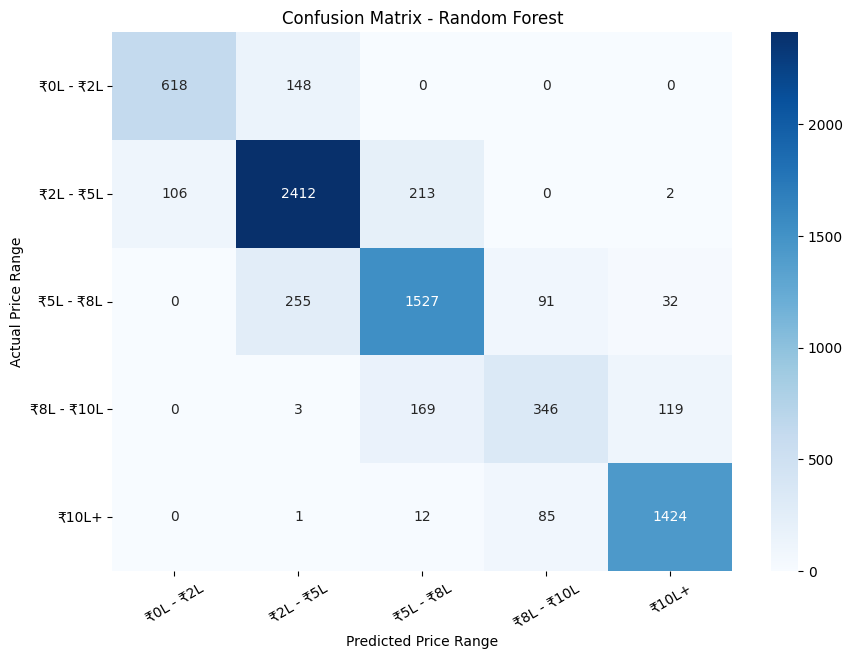

In [ ]:
plt.figure(figsize=(10,7))

class_names = [
    "₹0L - ₹2L",
    "₹2L - ₹5L",
    "₹5L - ₹8L",
    "₹8L - ₹10L",
    "₹10L+"
]

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")

plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.show()

# Interpretation of Confusion Matrix

The diagonal values represent correctly classified car price segments.

Higher diagonal values indicate better classification performance.

The off-diagonal values represent misclassifications where one price category was predicted as another.

## Cross Validation

K-Fold Cross Validation was used to ensure model reliability.

### Benefits:
- Reduces overfitting
- Ensures consistency
- Provides robust performance estimates

In [ ]:
cv_scores = cross_val_score(best_model, X_train, y_train, cv=3)

print("Cross Validation Scores:", cv_scores)
print("Mean CV Accuracy:", round(cv_scores.mean(),4))

Cross Validation Scores: [0.82378025 0.82328441 0.82515124]
Mean CV Accuracy: 0.8241


##Step 8: Hyperparameter Tuning

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", round(grid.best_score_,4))

Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best CV Score: 0.8255


## Final Tuned Model

In [ ]:
best_model = grid.best_estimator_

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Tuned Random Forest Model Ready.")

Tuned Random Forest Model Ready.


## Feature Importance

Feature importance was analyzed using the Random Forest model.

This helps identify which features most influence price classification.

Key features include:
- Car age
- Kilometers driven
- Brand
- Ownership

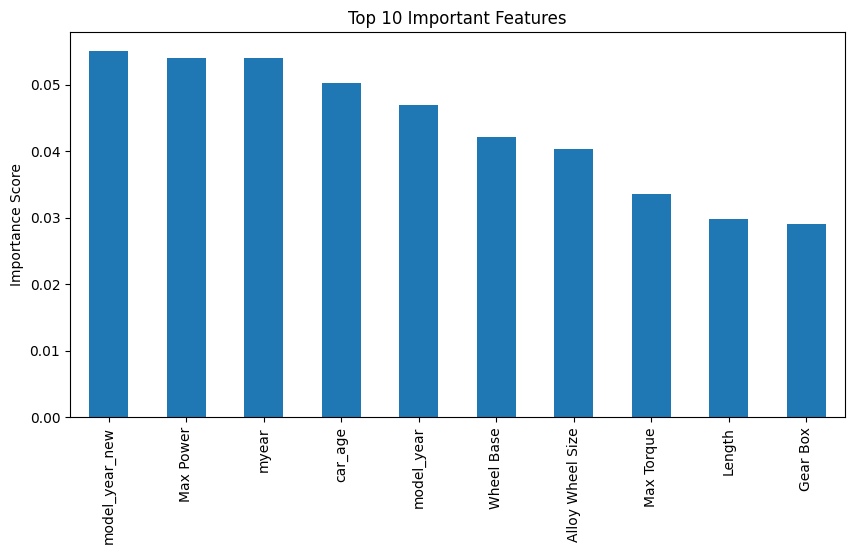

In [ ]:
importance = pd.Series(best_model.feature_importances_, index=X.columns)

importance.sort_values(ascending=False).head(10).plot(kind='bar', figsize=(10,5))

plt.title("Top 10 Important Features")
plt.ylabel("Importance Score")
plt.show()

# Interpretation of Feature Importance

The Random Forest model identified vehicle age, manufacturing year, engine performance, and vehicle dimensions as the most influential factors in predicting used car price category.

This indicates that both depreciation-related factors and vehicle specifications play a significant role in resale pricing.

In [ ]:
final_accuracy = accuracy_score(y_test, y_pred)

print("Final Tuned Accuracy:", round(final_accuracy,4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Final Tuned Accuracy: 0.8351

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.79      0.82       766
           1       0.85      0.88      0.87      2733
           2       0.79      0.80      0.80      1905
           3       0.66      0.53      0.59       637
           4       0.90      0.94      0.92      1522

    accuracy                           0.84      7563
   macro avg       0.81      0.79      0.80      7563
weighted avg       0.83      0.84      0.83      7563



##Save Final Trained Model

The trained model is saved so it can be reused later for deployment or prediction.

In [ ]:
joblib.dump(best_model, "used_car_random_forest_model.pkl")

print("Final model saved successfully.")

Final model saved successfully.


##Save Scaler

Since scaling was applied during preprocessing, the scaler should also be saved.

In [ ]:
joblib.dump(scaler, "used_car_scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


# Example Predictions on New Car Records

The table below shows sample unseen vehicles from the test set along with selected key input features and the predicted price category generated by the trained Random Forest model.

In [ ]:
labels = {
    0: "₹0L - ₹2L",
    1: "₹2L - ₹5L",
    2: "₹5L - ₹8L",
    3: "₹8L - ₹10L",
    4: "₹10L+"
}


sample_data = X_test.iloc[:5].copy()


predictions = best_model.predict(sample_data)


result_table = pd.DataFrame({
    "Car Model": sample_data["model"].values,
    "Manufacturing Year": sample_data["myear"].values,
    "KM Driven": sample_data["km"].values,
    "Max Power": sample_data["Max Power"].values,
    "Gear Box": sample_data["Gear Box"].values,
    "Actual Price Range": y_test[:5],
    "Predicted Price Range": predictions
})


result_table["Actual Price Range"] = result_table["Actual Price Range"].map(labels)
result_table["Predicted Price Range"] = result_table["Predicted Price Range"].map(labels)


result_table["Prediction Status"] = (
    result_table["Actual Price Range"] ==
    result_table["Predicted Price Range"]
).map({True: "Correct", False: "Incorrect"})


result_table

,Car Model,Manufacturing Year,KM Driven,Max Power,Gear Box,Actual Price Range,Predicted Price Range,Prediction Status
0,0.122951,-0.2,1.163729,0.000000,0.0,₹2L - ₹5L,₹2L - ₹5L,Correct
1,-0.770492,-0.2,1.071302,0.004614,0.0,₹2L - ₹5L,₹2L - ₹5L,Correct
2,-0.770492,0.4,0.145073,0.004614,0.0,₹5L - ₹8L,₹5L - ₹8L,Correct
3,-0.565574,1.0,-0.683347,0.569319,1.0,₹10L+,₹10L+,Correct
4,-0.647541,-0.8,0.438560,0.034602,1.0,₹2L - ₹5L,₹2L - ₹5L,Correct


## Real-World Applications

This model can be used in:

- Used car platforms
- Price range estimation systems
- Buyer decision support tools
- Seller pricing assistance

It provides quick and interpretable price category predictions.


# Final Conclusion

This project successfully developed a **Used Car Price Estimation Engine** using Machine Learning techniques on the CarDekho dataset. Instead of predicting an exact numerical price, the problem was formulated as a **multi-class classification task**, where vehicles were categorized into predefined price ranges such as ₹0L–₹2L, ₹2L–₹5L, ₹5L–₹8L, ₹8L–₹10L, and ₹10L+.

A complete end-to-end Machine Learning pipeline was implemented, including **data cleaning, missing value treatment, outlier handling using IQR capping, categorical encoding, train-test splitting, feature scaling using RobustScaler, model training, evaluation, cross-validation, and hyperparameter tuning**.

Multiple classification algorithms were compared, including Logistic Regression, KNN, SVM, Decision Tree, and Random Forest. After comparative evaluation, **Random Forest Classifier** emerged as the most suitable model due to its strong performance, robustness, and ability to capture complex non-linear relationships in the dataset.

The final tuned Random Forest model achieved strong predictive performance with reliable accuracy and balanced class-wise metrics. Confusion matrix analysis showed that most misclassifications occurred only between neighboring price ranges, which is expected in real-world resale pricing problems where adjacent categories often share similar characteristics.

Feature importance analysis further revealed that factors such as **manufacturing year, kilometers driven, model type, engine power, and transmission features** significantly influence used car pricing.

Overall, this project demonstrates how Machine Learning can be effectively used to assist buyers, sellers, and dealerships in estimating fair used car price ranges quickly and intelligently. The trained model and scaler were also saved for future deployment, making the solution practical and scalable for real-world applications.
